# Search evaluation: vector vs text vs RRF

Build a small ground-truth set by sampling indexed Wikifin chunks and asking an LLM to invent natural queries (Dutch, English, and French) that should retrieve each chunk. Then compare `vector_search`, `text_search`, and `rff_search` with **hit rate@k** and **MRR@k**, overall and **by query language**.

In [1]:
from __future__ import annotations

import json
import random

from dotenv import load_dotenv
load_dotenv(override=True)

from openai import OpenAI

from wikifin_rag.config import DEFAULT_LLM_MODEL, PROJECT_ROOT
from wikifin_rag.search import rff_search, text_search, vector_search

from pydantic import BaseModel
from concurrent.futures import ThreadPoolExecutor
from wikifin_rag.evaluation_utils import llm_structured_retry, map_progress, calc_price, sample_documents, generate_corpus_queries
import pandas as pd
from functools import reduce
from tqdm.auto import tqdm


# Evaluation knobs
SAMPLE_SIZE = 30
TOP_K = 10
SEED = 42
DOC_LANGUAGE = "nl"  # indexed corpus language filter
QUERY_LANGUAGES = ["nl", "en", "fr"]
NAMESPACE = "__default__"
INCLUDE_FIELDS = ["title", "section", "text", "source_url", "language"]

_client = OpenAI()


_QUERY_GEN_INSTRUCTIONS = """
You write evaluation queries for a Dutch personal-finance search index (Wikifin).

Given one document chunk, invent natural user questions/search queries in each
requested language that this chunk should retrieve as a relevant result.

Rules:
- Produce one query per requested language.
- Prefer realistic user questions over keyword dumps.
- Keep the same information need across languages (parallel translations of intent).
- Do not mention document IDs, chunk numbers, or that this is an evaluation.
- Do not quote the chunk verbatim at length; paraphrase the information need.
- The requested languages are: Dutch (nl), French (fr) and English (en)
  Include only the requested language keys.
""".strip()

In [3]:
_DATA_PATH = PROJECT_ROOT / "data"
_DATA_PATH.mkdir(exist_ok=True, parents=True)

## 1. Sample documents from the index

In [4]:
random.seed(SEED)
sample_docs = sample_documents(n=SAMPLE_SIZE, include_fields=INCLUDE_FIELDS)
print(f"Sampled {len(sample_docs)} usable {DOC_LANGUAGE} documents")
sample_docs[0]

Sampled 30 usable nl documents


{'_id': '0086962342dc497d#8',
 'language': 'nl',
 'section': 'Het onderzoek',
 'source_url': 'https://www.wikifin.be/nl/wikifin-school/online-oefenen-dankzij-financial-literacy-school',
 'text': 'schrijvingen voor ronde 3 van Financial Literacy @ School (schooljaar 2018-2019)\xa0zijn afgesloten.\n\n\n\n# AFGESLOTEN\xa0-\xa0RONDE 4: LESMATERIAAL OVER HET THEMA DE OVERHEID\n\nTweede of derde trimester schooljaar 2018-2019, Voor leerlingen van het 1ste\xa0en 2de\xa0jaar van de eerste graad secundair onderwijs\nDe inschrijvingen voor ronde 4 van Financial Literacy @ School (schooljaar 2018-2019)\xa0zijn afgesloten.',
 'title': 'Online oefenen dankzij Financial Literacy @ School'}

## 2. Generate ground-truth queries with an LLM

For each sampled chunk, the LLM invents parallel queries in Dutch, English, and French. The chunk `_id` is the relevant document for every language variant.

In [5]:
try:
    df_ground_truth = pd.read_csv(_DATA_PATH / "ground_truth-new.csv")
    ground_truth = df_ground_truth.to_dict(orient="records")
except FileNotFoundError:
    ground_truth, total_cost = generate_corpus_queries(sample_docs, file_path=_DATA_PATH / "ground_truth-new.csv")
    df_ground_truth = pd.DataFrame(ground_truth)
    print(total_cost)

In [6]:
df_ground_truth.head()

,query,query_language,reference_notes,relevant_id,title,section,text
0,Wanneer kan ik een huurcontract vroegtijdig op...,nl,['Een standaard huurcontract en een huurcontra...,0831243334a0b190#0,Wat is een huurcontract?,Vroegtijdige beëindiging,Een standaard huurcontract en een huurcontract...
1,"Can I end a standard lease early, and what not...",en,['A standard lease and a lease of more than ni...,0831243334a0b190#0,Wat is een huurcontract?,Vroegtijdige beëindiging,Een standaard huurcontract en een huurcontract...
2,"Puis-je résilier un bail de manière anticipée,...",fr,['Un bail standard et un bail de plus de neuf ...,0831243334a0b190#0,Wat is een huurcontract?,Vroegtijdige beëindiging,Een standaard huurcontract en een huurcontract...
3,Waar moet ik het startbedrag van het groeipakk...,nl,"['Het groeipakket, de geboortepremie en de kin...",15b7fe97818dccf7#0,De geboorte van een kind,Hoe krijg ik het startbedrag van het groeipakk...,Het groeipakket of de geboortepremie en de kin...
4,Where should I apply for the birth grant or st...,en,"['The growth allowance, birth grant and child ...",15b7fe97818dccf7#0,De geboorte van een kind,Hoe krijg ik het startbedrag van het groeipakk...,Het groeipakket of de geboortepremie en de kin...


In [7]:
by_lang = df_ground_truth.query_language.value_counts().to_dict()
print(f"Built {len(ground_truth)} ground-truth pairs: {by_lang}")

Built 150 ground-truth pairs: {'nl': 50, 'en': 50, 'fr': 50}


## 3. Evaluate retrieval metrics

- **Hit rate@k**: fraction of queries where the relevant document appears in the top-k results.
- **MRR@k**: mean reciprocal rank of the relevant document (0 if missing from the top-k).

Metrics are reported overall and broken down by query language so Dutch vs non-Dutch impact is visible.

In [8]:
def reciprocal_rank(relevance):
    for rank, match in enumerate(relevance, start=1):
        if match == 1:
            return 1.0 / rank
    return 0.0

In [9]:
def compute_relevance_document(q, search_function) -> list[int]:
    doc_id = q["relevant_id"]
    results = search_function(query=q["query"])
    results = list(map(json.loads, results))

    return [int(d["_id"] == doc_id) for d in results]


def compute_relevance_corpus(ground_truth, search_function):
    relevance_total = map(
        lambda q: compute_relevance_document(q, search_function),
        tqdm(ground_truth)
        )

    return list(relevance_total)


def evaluate_search(ground_truth_df, search_function):
    n = len(ground_truth_df)
    if n == 0:
        return {"n": 0, "hit_rate": 0.0, "mrr": 0.0, "rows": []}

    df = ground_truth_df.copy()

    df["search_function"] = search_function.__name__
    df["relevance"] = df.apply(lambda row: compute_relevance_document(row, search_function), axis=1)
    df["rr"] = df.relevance.map(reciprocal_rank)
    df["hit"] = df.rr > 0
    df["rank"] = 1 / df["rr"]

    metrics = {
        "n": n,
        "hit_rate": df.hit.sum() / n,
        "mrr": df.rr.sum() / n,
    }

    return df, metrics

In [10]:
def summarize_metrics(result: dict, k: int = TOP_K) -> dict:
    return {
        "n": result["n"],
        f"hit_rate@{k}": float(round(result["hit_rate"], 4)),
        f"mrr@{k}": float(round(result["mrr"], 4)),
    }

In [11]:
search_fns = {
    "vector_search": vector_search,
    "text_search": text_search,
    "rff_search": rff_search,
}

metrics = {}
eval_dfs = []
for name, fn in search_fns.items():
    print(f"Evaluating {name}...")
    fn_eval_df, fn_eval_metrics = evaluate_search(df_ground_truth, fn)
    metrics[name] = fn_eval_metrics
    eval_dfs.append(fn_eval_df)

eval_df = pd.concat(eval_dfs)

overall_summary = {
    name: summarize_metrics(result)
    for name, result in metrics.items()
}
overall_summary

Evaluating vector_search...
Evaluating text_search...
Evaluating rff_search...


{'vector_search': {'n': 150, 'hit_rate@10': 0.8067, 'mrr@10': 0.5868},
 'text_search': {'n': 150, 'hit_rate@10': 0.4333, 'mrr@10': 0.285},
 'rff_search': {'n': 150, 'hit_rate@10': 0.9533, 'mrr@10': 0.7507}}

## 4. Results

Overall scores, then the same metrics by query language, plus the drop from Dutch (`nl`) to each non-Dutch language.

In [12]:
overall = eval_df.groupby("search_function").agg(
    n=pd.NamedAgg(column="hit", aggfunc="count"),
    hit_rate=pd.NamedAgg(column="hit", aggfunc="mean"),
    mrr=pd.NamedAgg(column="rr", aggfunc="mean")
).round(3)

print("Overall")
display(overall)

Overall


,n,hit_rate,mrr
search_function,,,
rff_search,150,0.953,0.751
text_search,150,0.433,0.285
vector_search,150,0.807,0.587


In [13]:
by_language = eval_df.groupby(["search_function", "query_language"]).agg(
    hit_rate=pd.NamedAgg(column="hit", aggfunc="mean"),
    mrr=pd.NamedAgg(column="rr", aggfunc="mean")
).round(3)

print("By query language")
display(by_language)

By query language


hit_rate    mrr
search_function query_language                 
rff_search      en                  0.92  0.710
                fr                  0.94  0.753
                nl                  1.00  0.789
text_search     en                  0.22  0.082
                fr                  0.16  0.052
                nl                  0.92  0.721
vector_search   en                  0.74  0.490
                fr                  0.72  0.434
                nl                  0.96  0.837

In [14]:
metrics_dutch = by_language[(by_language.index.get_level_values("query_language") == "nl")]
metrics_non_dutch = by_language[(by_language.index.get_level_values("query_language") != "nl")]

metrics_language_gap = metrics_non_dutch.sub(
    metrics_dutch.droplevel("query_language"),
    level="search_function",
)

print("Non-Dutch impact vs Dutch")
display(metrics_language_gap)


Non-Dutch impact vs Dutch


hit_rate    mrr
search_function query_language                 
rff_search      en                 -0.08 -0.079
                fr                 -0.06 -0.036
text_search     en                 -0.70 -0.639
                fr                 -0.76 -0.669
vector_search   en                 -0.22 -0.347
                fr                 -0.24 -0.403

### Plots


In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

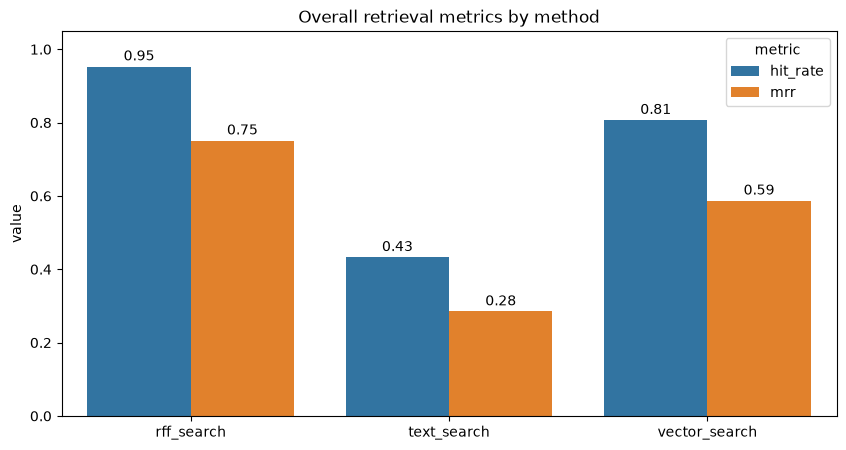

In [16]:
df = overall.reset_index().melt(
    id_vars=["search_function"],
    value_vars=["hit_rate", "mrr"],
    var_name="metric"
)

plt.figure(figsize=(10, 5))
plt.title("Overall retrieval metrics by method")
ax = sns.barplot(df, x="search_function", y="value", hue="metric")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=2)
plt.xlabel("")
plt.ylim(0, 1.05)
plt.show()

Text(0.5, 1.0, 'MRR by query language')

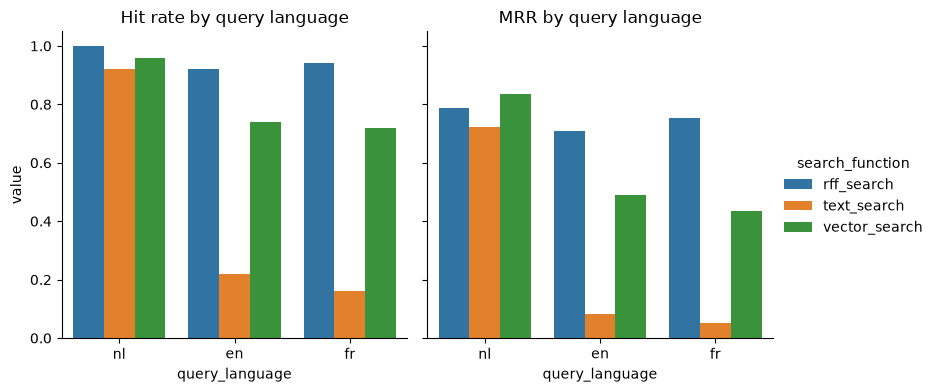

In [17]:
df = by_language.reset_index().melt(
    id_vars=["search_function", "query_language"],
    value_vars=["hit_rate", "mrr"],
    var_name="metric"
)

g = sns.catplot(
    data=df,
    x="query_language",
    y="value",
    hue="search_function",
    col="metric",
    col_order=["hit_rate", "mrr"],
    kind="bar",
    order=["nl", "en", "fr"],
    errorbar=None,
    height=4,
    aspect=1,
)
g.set(ylim=(0, 1.05))
g.axes[0, 0].set_title("Hit rate by query language")
g.axes[0, 1].set_title("MRR by query language")

### Spot-check non-Dutch failures

Inspect English/French queries where hybrid search missed the ground-truth document.

In [18]:
eval_df.head()

eval_df.loc[
    (eval_df.search_function == "rff_search") &
    (eval_df.query_language != "nl") &
    (~eval_df.hit),
    ["query", "query_language", "relevant_id"]
].head().to_dict(orient="records")

[{'query': 'Do I need to see a notary when someone dies, and what can the notary do with the inheritance?',
  'query_language': 'en',
  'relevant_id': '13829129605ed41f#0'},
 {'query': 'Faut-il aller אצל un notaire quand quelqu’un décède, et à quoi peut-il servir pour la succession ?',
  'query_language': 'fr',
  'relevant_id': '13829129605ed41f#0'},
 {'query': 'What does a health insurance fund do in the compulsory health insurance system?',
  'query_language': 'en',
  'relevant_id': '129126d93f4b58e6#1'},
 {'query': 'Qu’est-ce qu’une carte de crédit et comment sont remboursés les paiements ou retraits d’argent ?',
  'query_language': 'fr',
  'relevant_id': '01ae0963612d7749#0'},
 {'query': 'What does the surviving spouse inherit when you are married under separation of property?',
  'query_language': 'en',
  'relevant_id': '0bf89909db8168b0#2'}]